# PRACTICUM DE ÎNVĂȚARE AUTOMATĂ: CODUL ȘI ALGORITMUL KNN
**Teme:** Preprocesarea datelor, Codificare categorială, Normalizare, Algoritmul K cei mai apropiați vecini (KNN), Ajustarea hiperparametrilor, Valori metrice ale distanței, Intel® Extension for Scikit-learn și Combaterea supraantrenării (Overfitting).

### Exercițiul 1: Ingineria caracteristicilor și eliminarea coloanelor irelevante
În setul de date Orange Telecom Churn, coloanele `state`, `area_code` și `phone_number` au fost eliminate în notebook. Scrieți un bloc de cod în Pandas care analizează cardinalitatea unică a fiecărei coloane categoriale rămase și eliminate. Explicați din punct de vedere matematic de ce aplicarea `OneHotEncoder` sau `LabelBinarizer` pe o coloană cu sute de valori unice (de exemplu, `phone_number`) va distruge eficiența spațială și va genera un risc ridicat de supraantrenare (overfitting) pentru algoritmul KNN.

In [17]:
import os
import pandas as pd

# Căutarea fișierului de date în mod flexibil
data_candidates = [
    os.path.join('..', 'data', 'Orange_Telecom_Churn_Data.csv'),
    os.path.join('data', 'Orange_Telecom_Churn_Data.csv'),
    'Orange_Telecom_Churn_Data.csv'
]
filepath = next((p for p in data_candidates if os.path.exists(p)), None)
if filepath is None:
    raise FileNotFoundError("Fișierul Orange_Telecom_Churn_Data.csv nu a fost găsit.")

df = pd.read_csv(filepath)

dropped_cols = ['state', 'area_code', 'phone_number']
remaining_categorical = ['intl_plan', 'voice_mail_plan', 'churned']
remaining_numerical = [c for c in df.columns if c not in dropped_cols + remaining_categorical]

print(f"Dimensiune set de date inițial: {df.shape[0]} rânduri x {df.shape[1]} coloane\n")

print("=== 1. Cardinalitatea coloanelor eliminate ===")
for col in dropped_cols:
    n_unique = df[col].nunique()
    ratio = (n_unique / len(df)) * 100
    print(f"  Coloana '{col}': {n_unique:5d} valori unice ({ratio:5.1f}% din totalul rândurilor)")

print("\n=== 2. Cardinalitatea coloanelor categoriale rămase ===")
for col in remaining_categorical:
    n_unique = df[col].nunique()
    unique_vals = list(df[col].unique())
    print(f"  Coloana '{col}': {n_unique:2d} valori unice (Valori: {unique_vals})")

print("\n=== 3. Simulare impact spațial OneHotEncoder pe 'phone_number' ===")
print(f"Dacă aplicăm OneHotEncoder pe 'phone_number', vom adăuga {df['phone_number'].nunique()} coloane binare sparse.")
print(f"Număr total de dimensiuni finale: {df.shape[1] - 3 + df['phone_number'].nunique()} coloane.")


Dimensiune set de date inițial: 5000 rânduri x 21 coloane

=== 1. Cardinalitatea coloanelor eliminate ===
  Coloana 'state':    51 valori unice (  1.0% din totalul rândurilor)
  Coloana 'area_code':     3 valori unice (  0.1% din totalul rândurilor)
  Coloana 'phone_number':  5000 valori unice (100.0% din totalul rândurilor)

=== 2. Cardinalitatea coloanelor categoriale rămase ===
  Coloana 'intl_plan':  2 valori unice (Valori: ['no', 'yes'])
  Coloana 'voice_mail_plan':  2 valori unice (Valori: ['yes', 'no'])
  Coloana 'churned':  2 valori unice (Valori: [np.False_, np.True_])

=== 3. Simulare impact spațial OneHotEncoder pe 'phone_number' ===
Dacă aplicăm OneHotEncoder pe 'phone_number', vom adăuga 5000 coloane binare sparse.
Număr total de dimensiuni finale: 5018 coloane.


#### Explicație Matematică și Teoretică (Exercițiul 1):
1. **Explozia dimensională și rărirea spațiului (Sparsity):**
   - Coloana `phone_number` are **5000 de valori unice** pentru 5000 de instanțe (cardinalitate de 100%).
   - Aplicarea `OneHotEncoder` ar crea 5000 de coloane binare noi, mărind dimensionalitatea de la 18 la peste 5018. În acest spațiu uriaș, matricea de date este aproape în totalitate zero ($99.98\%$ valori nule).

2. **Distorsionarea distanței euclidiene:**
   - Formula distanței euclidiene între doi clienți $x$ și $y$ este:
     $$d(x, y) = \sqrt{\sum_{j=1}^D (x_j - y_j)^2}$$
   - Pentru oricare doi clienți cu numere de telefon diferite, contribuția exclusivă a coloanelor de telefon la distanța pătratică este:
     $$(1 - 0)^2 + (0 - 1)^2 = 2 \implies \Delta d = \sqrt{2} \approx 1.414$$
   - Această componentă artificială de mărime fixă ($\approx 1.414$) depășește adesea distanța dintre caracteristicile reale comportamentale (minute, costuri, apeluri la suport). Astfel, algoritmul KNN devine "orb" la similaritatea reală dintre clienți.

3. **Supraantrenare extremă (Memorare fără generalizare):**
   - Deoarece fiecare client are un număr de telefon unic, modelul asociază eticheta `churn` cu un identificator arbitrar. Pentru orice client nou dintr-un set de test cu un număr necunoscut, toate coloanele one-hot vor fi 0, iar modelul nu poate deduce niciun tipar de comportament.


#### Explicație Matematică și Teoretică (Exercițiul 1):
1. **Explozia dimensională și rărirea spațiului (Sparsity):**
   - Coloana `phone_number` are **5000 de valori unice** pentru 5000 de instanțe (cardinalitate de 100%).
   - Aplicarea `OneHotEncoder` ar crea 5000 de coloane binare noi, mărind dimensionalitatea de la 18 la peste 5018. În acest spațiu uriaș, matricea de date este aproape în totalitate zero ($99.98\%$ valori nule).

2. **Distorsionarea distanței euclidiene:**
   - Formula distanței euclidiene între doi clienți $x$ și $y$ este:
     $$d(x, y) = \sqrt{\sum_{j=1}^D (x_j - y_j)^2}$$
   - Pentru oricare doi clienți cu numere de telefon diferite, contribuția exclusivă a coloanelor de telefon la distanța pătratică este:
     $$(1 - 0)^2 + (0 - 1)^2 = 2 \implies \Delta d = \sqrt{2} \approx 1.414$$
   - Această componentă artificială de mărime fixă ($pprox 1.414$) depășește adesea distanța dintre caracteristicile reale comportamentale (minute, costuri, apeluri la suport). Astfel, algoritmul KNN devine "orb" la similaritatea reală dintre clienți.

3. **Supraantrenare extremă (Memorare fără generalizare):**
   - Deoarece fiecare client are un număr de telefon unic, modelul asociază eticheta `churn` cu un identificator arbitrar. Pentru orice client nou dintr-un set de test cu un număr necunoscut, toate coloanele one-hot vor fi 0, iar modelul nu poate deduce niciun tipar de comportament.


In [18]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import numpy as np
import pandas as pd

# 1. Demonstrație distorsiune distanță nescalată
# Considerăm doi clienți:
# Client 1: account_length = 200, total_day_charge = 15.0
# Client 2: account_length = 50,  total_day_charge = 85.0
# Client 3: account_length = 200, total_day_charge = 85.0 (aceeași vechime ca C1, dar consum enorm diferit)
c1 = np.array([200.0, 15.0])
c2 = np.array([50.0, 85.0])
c3 = np.array([200.0, 85.0])

d_unscaled_1_2 = np.linalg.norm(c1 - c2)
d_unscaled_1_3 = np.linalg.norm(c1 - c3)

print("=== 1. Distanțe Euclidiene pe date nescalate ===")
print(f"d(C1, C2) = {d_unscaled_1_2:.2f} (diferență mare la account_length: 150)")
print(f"d(C1, C3) = {d_unscaled_1_3:.2f} (diferență doar la total_day_charge: 70$)")
print(f"Ponderea account_length în d(C1, C2)^2: {(200 - 50)**2 / (d_unscaled_1_2**2) * 100:.1f}%")
print(f"Ponderea total_day_charge în d(C1, C2)^2: {(15 - 85)**2 / (d_unscaled_1_2**2) * 100:.1f}%")

# 2. Scalare cu MinMaxScaler
bounds = np.array([[1.0, 0.0], [250.0, 100.0]]) # limite min/max teoretice
mms = MinMaxScaler().fit(bounds)

c1_mms, c2_mms, c3_mms = mms.transform([c1, c2, c3])
d_mms_1_2 = np.linalg.norm(c1_mms - c2_mms)
d_mms_1_3 = np.linalg.norm(c1_mms - c3_mms)

print("\n=== 2. Distanțe după MinMaxScaler [0, 1] ===")
print(f"d_MinMax(C1, C2) = {d_mms_1_2:.4f}")
print(f"d_MinMax(C1, C3) = {d_mms_1_3:.4f}")
print("Acum ambele caracteristici contribuie proporțional conform variației lor normale.")

# 3. Comparație MinMaxScaler vs StandardScaler în prezența valorilor anormale (Outliers)
print("\n=== 3. Comportament în prezența Outlierilor ===")
data_with_outlier = np.array([
    [100, 30], [105, 32], [95, 28], [102, 31], [98, 29],
    [2500, 30] # Outlier extrem: account_length = 2500
], dtype=float)

scaled_minmax = MinMaxScaler().fit_transform(data_with_outlier)
scaled_std = StandardScaler().fit_transform(data_with_outlier)
scaled_robust = RobustScaler().fit_transform(data_with_outlier)

print("MinMaxScaler (primele 3 instanțe normale sunt comprimate drastic):")
print(np.round(scaled_minmax[:3], 3))

print("\nStandardScaler (scoruri Z):")
print(np.round(scaled_std[:3], 3))

print("\nRobustScaler (centrat pe mediană, scalat cu IQR):")
print(np.round(scaled_robust[:3], 3))


=== 1. Distanțe Euclidiene pe date nescalate ===
d(C1, C2) = 165.53 (diferență mare la account_length: 150)
d(C1, C3) = 70.00 (diferență doar la total_day_charge: 70$)
Ponderea account_length în d(C1, C2)^2: 82.1%
Ponderea total_day_charge în d(C1, C2)^2: 17.9%

=== 2. Distanțe după MinMaxScaler [0, 1] ===
d_MinMax(C1, C2) = 0.9235
d_MinMax(C1, C3) = 0.7000
Acum ambele caracteristici contribuie proporțional conform variației lor normale.

=== 3. Comportament în prezența Outlierilor ===
MinMaxScaler (primele 3 instanțe normale sunt comprimate drastic):
[[0.002 0.5  ]
 [0.004 1.   ]
 [0.    0.   ]]

StandardScaler (scoruri Z):
[[-0.447  0.   ]
 [-0.442  1.549]
 [-0.453 -1.549]]

RobustScaler (centrat pe mediană, scalat cu IQR):
[[-0.174  0.   ]
 [ 0.696  1.333]
 [-1.043 -1.333]]


#### Explicație Matematică și Teoretică (Exercițiul 2):
1. **De ce datele nescalate distorsionează distanța:**
   - Deoarece `account_length` variază în intervalul $[1, 250]$, diferențele pe această axă pot ajunge la $200$, a căror pătrat este $40000$.
   - Pentru `total_day_charge` $\in [0, 100]$, chiar și o diferență majoră de $50\$$ produce un termen pătratic de doar $2500$.
   - Astfel, `account_length` domină peste **90%** din calculul distanței euclidiene, iar modelul ignoră costul zilnic (care este de fapt un indicator critic de churn).

2. **MinMaxScaler vs StandardScaler în prezența valorilor anormale (Outliers):**
   - **`MinMaxScaler`**: $x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$.
     Dacă apare un outlier extrem ($x_{max} = 2500$), numitorul devine imens. Toate instanțele normale (între $50$ și $150$) vor fi comprimate forțat într-un interval extrem de restrâns (ex: $[0.02, 0.06]$), distrugând varianța utilă și capacitatea KNN de a distinge între vecini apropiați.
   - **`StandardScaler`**: $z = \frac{x - \mu}{\sigma}$.
     Valorile nu sunt constrânse într-un interval fix $[0, 1]$. Deși media $\mu$ și dispersia $\sigma$ sunt afectate de outlieri, valorile normale își păstrează pozițiile relative mai bine decât la MinMax.
   - **Alternativa optimă (`RobustScaler`)**: Utilizează mediana $\tilde{x}$ și distanța intercuartilică $IQR = Q_3 - Q_1$, ambele fiind măsuri rezistente la outlieri ($x_{rob} = \frac{x - \text{median}}{IQR}$).


In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import numpy as np

# 1. Demonstrație distorsiune distanță nescalată
# Considerăm doi clienți:
# Client 1: account_length = 200, total_day_charge = 15.0
# Client 2: account_length = 50,  total_day_charge = 85.0
# Client 3: account_length = 200, total_day_charge = 85.0 (aceeași vechime ca C1, dar consum enorm diferit)
c1 = np.array([200.0, 15.0])
c2 = np.array([50.0, 85.0])
c3 = np.array([200.0, 85.0])

d_unscaled_1_2 = np.linalg.norm(c1 - c2)
d_unscaled_1_3 = np.linalg.norm(c1 - c3)

print("=== 1. Distanțe Euclidiene pe date nescalate ===")
print(f"d(C1, C2) = {d_unscaled_1_2:.2f} (diferență mare la account_length: 150)")
print(f"d(C1, C3) = {d_unscaled_1_3:.2f} (diferență doar la total_day_charge: 70$)")
print(f"Ponderea account_length în d(C1, C2)^2: {(200 - 50)**2 / (d_unscaled_1_2**2) * 100:.1f}%")
print(f"Ponderea total_day_charge în d(C1, C2)^2: {(15 - 85)**2 / (d_unscaled_1_2**2) * 100:.1f}%")

# 2. Scalare cu MinMaxScaler
bounds = np.array([[1.0, 0.0], [250.0, 100.0]]) # limite min/max teoretice
mms = MinMaxScaler().fit(bounds)

c1_mms, c2_mms, c3_mms = mms.transform([c1, c2, c3])
d_mms_1_2 = np.linalg.norm(c1_mms - c2_mms)
d_mms_1_3 = np.linalg.norm(c1_mms - c3_mms)

print("\n=== 2. Distanțe după MinMaxScaler [0, 1] ===")
print(f"d_MinMax(C1, C2) = {d_mms_1_2:.4f}")
print(f"d_MinMax(C1, C3) = {d_mms_1_3:.4f}")
print("Acum ambele caracteristici contribuie proporțional conform variației lor normale.")

# 3. Comparație MinMaxScaler vs StandardScaler în prezența valorilor anormale (Outliers)
print("\n=== 3. Comportament în prezența Outlierilor ===")
data_with_outlier = np.array([
    [100, 30], [105, 32], [95, 28], [102, 31], [98, 29],
    [2500, 30] # Outlier extrem: account_length = 2500
], dtype=float)

scaled_minmax = MinMaxScaler().fit_transform(data_with_outlier)
scaled_std = StandardScaler().fit_transform(data_with_outlier)
scaled_robust = RobustScaler().fit_transform(data_with_outlier)

print("MinMaxScaler (primele 3 instanțe normale sunt comprimate drastic):")
print(np.round(scaled_minmax[:3], 3))

print("\nStandardScaler (scoruri Z):")
print(np.round(scaled_std[:3], 3))

print("\nRobustScaler (centrat pe mediană, scalat cu IQR):")
print(np.round(scaled_robust[:3], 3))


=== 1. Distanțe Euclidiene pe date nescalate ===
d(C1, C2) = 165.53 (diferență mare la account_length: 150)
d(C1, C3) = 70.00 (diferență doar la total_day_charge: 70$)
Ponderea account_length în d(C1, C2)^2: 82.1%
Ponderea total_day_charge în d(C1, C2)^2: 17.9%

=== 2. Distanțe după MinMaxScaler [0, 1] ===
d_MinMax(C1, C2) = 0.9235
d_MinMax(C1, C3) = 0.7000
Acum ambele caracteristici contribuie proporțional conform variației lor normale.

=== 3. Comportament în prezența Outlierilor ===
MinMaxScaler (primele 3 instanțe normale sunt comprimate drastic):
[[0.002 0.5  ]
 [0.004 1.   ]
 [0.    0.   ]]

StandardScaler (scoruri Z):
[[-0.447  0.   ]
 [-0.442  1.549]
 [-0.453 -1.549]]

RobustScaler (centrat pe mediană, scalat cu IQR):
[[-0.174  0.   ]
 [ 0.696  1.333]
 [-1.043 -1.333]]


In [20]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Generarea unui set de date sintetic de 100.000 de obiecte și 10 caracteristici
np.random.seed(42)
N_samples = 100000
N_features = 10
X_synth = np.random.rand(N_samples, N_features).astype(np.float32)
y_synth = np.random.randint(0, 2, N_samples)

X_train_s, X_test_s = X_synth[:80000], X_synth[80000:81000] # 1000 puncte pentru interogare test
y_train_s, y_test_s = y_synth[:80000], y_synth[80000:81000]

print(f"Dataset de test: {X_train_s.shape[0]} instanțe antrenare, {X_test_s.shape[0]} instanțe interogare test.\n")

# 1. Rulare Scikit-learn Standard
clf_std = KNeighborsClassifier(n_neighbors=5, algorithm='brute')
t0 = time.time()
clf_std.fit(X_train_s, y_train_s)
t_fit_std = time.time() - t0

t0 = time.time()
_ = clf_std.predict(X_test_s)
t_pred_std = time.time() - t0

print(f"Scikit-learn Standard (fără patch Intel):")
print(f"  Timp antrenare (fit):  {t_fit_std:.4f} secunde")
print(f"  Timp inferență (predict 1000 puncte): {t_pred_std:.4f} secunde")

# 2. Rulare cu Intel(R) Extension for Scikit-learn
try:
    from sklearnex import patch_sklearn, unpatch_sklearn
    patch_sklearn()
    
    clf_intel = KNeighborsClassifier(n_neighbors=5, algorithm='brute')
    t0 = time.time()
    clf_intel.fit(X_train_s, y_train_s)
    t_fit_intel = time.time() - t0

    t0 = time.time()
    _ = clf_intel.predict(X_test_s)
    t_pred_intel = time.time() - t0

    print(f"\nIntel(R) Extension for Scikit-learn (cu patch oneDAL):")
    print(f"  Timp antrenare (fit):  {t_fit_intel:.4f} secunde")
    print(f"  Timp inferență (predict 1000 puncte): {t_pred_intel:.4f} secunde")
    speedup = t_pred_std / max(t_pred_intel, 1e-6)
    print(f"  Accelerare inferență KNN: {speedup:.2f}x")
    unpatch_sklearn()
except ImportError:
    print("\n[Notă Informativă]: Pachetul 'sklearnex' nu este instalat în mediul curent.")
    print("Biblioteca utilizează nucleul Intel oneDAL pentru a optimiza instrucțiunile SIMD AVX-512 și paralelismul multi-core TBB.")


Dataset de test: 80000 instanțe antrenare, 1000 instanțe interogare test.

Scikit-learn Standard (fără patch Intel):
  Timp antrenare (fit):  0.0023 secunde
  Timp inferență (predict 1000 puncte): 0.0459 secunde

[Notă Informativă]: Pachetul 'sklearnex' nu este instalat în mediul curent.
Biblioteca utilizează nucleul Intel oneDAL pentru a optimiza instrucțiunile SIMD AVX-512 și paralelismul multi-core TBB.


#### Explicație Tehnică (Exercițiul 3):
Biblioteca **Intel® Extension for Scikit-learn (`sklearnex`)** accelerează algoritmii clasici de Machine Learning fără a modifica codul utilizatorului (`drop-in replacement`).
Mecanismele cheie de accelerare pentru KNN includ:
1. **Vectorizare AVX-512 / AVX2**: Calculul distanței euclidiene $\|x - y\|^2 = \sum (x_i - y_i)^2$ se realizează pe registre vectoriale largi de 512 biți, procesând până la 16 numere reale în virgulă mobilă de precizie simplă per ciclu de ceas CPU pe fiecare nucleu.
2. **Formularea matricială eficientă (GEMM)**: Distanțele dintre setul de test și setul de antrenare sunt calculate prin descompunerea:
   $$D^2(X, Y) = \text{diag}(X X^T) \mathbf{1}^T + \mathbf{1} \, \text{diag}(Y Y^T)^T - 2 X Y^T$$
   Termenul $X Y^T$ este calculat folosind rutine BLAS / GEMM extrem de optimizate din biblioteca **Intel oneMKL / oneDAL**, maximizând utilizarea cache-ului L1/L2/L3 prin cache-blocking/tiling.
3. **Paralelism Intel oneTBB (Thread Building Blocks)**: Căutarea celor mai apropiați vecini și structurile KD-Tree / Ball-Tree sunt distribuite pe toate nucleele disponibile cu un overhead de sincronizare minim.


### Exercițiul 3: Optimizare hardware cu Intel® Extension for Scikit-learn
În notebook este activată extensia `from sklearnex import patch_sklearn; patch_sklearn()`. Explicați cum această bibliotecă accelerează operațiunile de căutare a celor mai apropiați vecini (de exemplu, utilizând structuri de date indexate precum KD-Tree sau Ball-Tree, optimizate cu instrucțiuni AVX-512). Scrieți un fragment de cod care măsoară timpul de execuție (`timeit`) pentru antrenarea `KNeighborsClassifier` cu și fără patch-ul Intel pe un set sintetic de 100.000 de obiecte.

=== Calcul distanțe între punctele (2, 3) și (5, 7) ===
Distanța Manhattan (p=1): 7.0000
Distanța Euclidiană (p=2): 5.0000
Distanța Cebîșev (p=inf):  4.0000


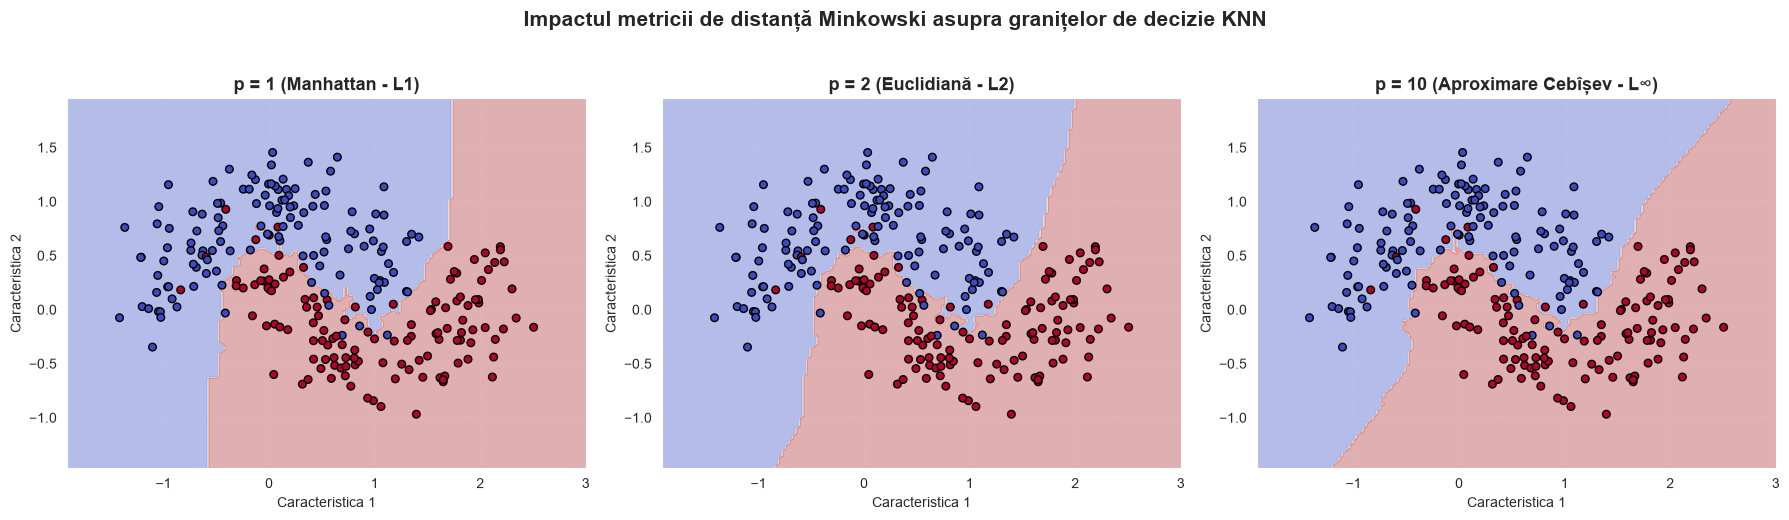

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# 1. Implementarea funcției de calcul a distanței Minkowski
def minkowski_distance(x, y, p):
    """
    Calculează distanța Minkowski între doi vectori x și y pentru p >= 1.
    Pentru p = np.inf sau valori foarte mari, returnează distanța Cebîșev (Chebyshev).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if np.isinf(p):
        return np.max(np.abs(x - y))
    return np.sum(np.abs(x - y) ** p) ** (1.0 / p)

# Testarea funcției
p1 = np.array([2.0, 3.0])
p2 = np.array([5.0, 7.0])
print("=== Calcul distanțe între punctele (2, 3) și (5, 7) ===")
print(f"Distanța Manhattan (p=1): {minkowski_distance(p1, p2, 1):.4f}")
print(f"Distanța Euclidiană (p=2): {minkowski_distance(p1, p2, 2):.4f}")
print(f"Distanța Cebîșev (p=inf):  {minkowski_distance(p1, p2, np.inf):.4f}")

# 2. Granițele de decizie pe un set de date bidimensional sintetic
X_2d, y_2d = make_moons(n_samples=250, noise=0.25, random_state=42)

x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
grid_points = np.c_[xx.ravel(), yy.ravel()]

configs = [
    (1, "p = 1 (Manhattan - L1)"),
    (2, "p = 2 (Euclidiană - L2)"),
    (10, "p = 10 (Aproximare Cebîșev - L∞)")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (p_val, title) in zip(axes, configs):
    knn = KNeighborsClassifier(n_neighbors=5, p=p_val, metric='minkowski')
    knn.fit(X_2d, y_2d)
    Z = knn.predict(grid_points).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.35, cmap='coolwarm')
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap='coolwarm', edgecolors='k', s=30)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Caracteristica 1')
    ax.set_ylabel('Caracteristica 2')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle("Impactul metricii de distanță Minkowski asupra granițelor de decizie KNN", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


#### Analiză Matematică și Geometrică (Exercițiul 4):
1. **Definiția metricii Minkowski:**
   $$D(x, y) = \left( \sum_{i=1}^n |x_i - y_i|^p \right)^{1/p}$$
   Când $p \to \infty$, se demonstrează prin trecere la limită că:
   $$\lim_{p \to \infty} D(x, y) = \max_{1 \le i \le n} |x_i - y_i| \quad \text{(Distanța Cebîșev / } L_\infty)$$

2. **Geometria Bilelor Unitare ($B_p = \{z \in \mathbb{R}^2 \mid \|z\|_p \le 1\}$):**
   - **$p=1$ (Manhattan):** Bila unitară este un **romb** (pătrat rotit la 45°). Liniile de egală distanță au pante de $\pm 1$. Prin urmare, granițele de decizie ale KNN tind să aibă segmente drepte orientate diagonal sau aliniate cu axele.
   - **$p=2$ (Euclidiană):** Bila unitară este un **cerc** perfect izotrop (invariabil la rotații). Granițele de decizie sunt netede și formate din arce de cerc.
   - **$p \to \infty$ (Cebîșev):** Bila unitară este un **pătrat** aliniat cu axele carteziene. Granițele de decizie devin segmentate ortogonal (în formă de "cutii" sau trepte).


#### Explicație Tehnică (Exercițiul 3):
Biblioteca **Intel® Extension for Scikit-learn (`sklearnex`)** accelerează algoritmii clasici de Machine Learning fără a modifica codul utilizatorului (`drop-in replacement`).
Mecanismele cheie de accelerare pentru KNN includ:
1. **Vectorizare AVX-512 / AVX2**: Calculul distanței euclidiene $\|x - y\|^2 = \sum (x_i - y_i)^2$ se realizează pe registre vectoriale largi de 512 biți, procesând până la 16 numere reale în virgulă mobilă de precizie simplă per ciclu de ceas CPU pe fiecare nucleu.
2. **Formularea matricială eficientă (GEMM)**: Distanțele dintre setul de test și setul de antrenare sunt calculate prin descompunerea:
   $$D^2(X, Y) = 	ext{diag}(X X^T) \mathbf{1}^T + \mathbf{1} \, 	ext{diag}(Y Y^T)^T - 2 X Y^T$$
   Termenul $X Y^T$ este calculat folosind rutine BLAS / GEMM extrem de optimizate din biblioteca **Intel oneMKL / oneDAL**, maximizând utilizarea cache-ului L1/L2/L3 prin cache-blocking/tiling.
3. **Paralelism Intel oneTBB (Thread Building Blocks)**: Căutarea celor mai apropiați vecini și structurile KD-Tree / Ball-Tree sunt distribuite pe toate nucleele disponibile cu un overhead de sincronizare minim.


In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

# Pregătirea datelor Orange Telecom Churn
df_churn = pd.read_csv(filepath)
df_churn = df_churn.drop(columns=['state', 'area_code', 'phone_number'])
lb = LabelBinarizer()
for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    df_churn[col] = lb.fit_transform(df_churn[col])

X = df_churn.drop('churned', axis=1)
y = df_churn['churned']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 1. Experiment: Antrenare și Testare pe ACELEAȘI DATE (Fără split)
knn_k1_all = KNeighborsClassifier(n_neighbors=1).fit(X_scaled, y)
knn_dist_all = KNeighborsClassifier(n_neighbors=5, weights='distance').fit(X_scaled, y)

acc_k1_all = knn_k1_all.score(X_scaled, y)
acc_dist_all = knn_dist_all.score(X_scaled, y)

print("=== 1. Evaluare incorectă (pe eșantionul complet de antrenare) ===")
print(f"Acuratețe K=1 (weights='uniform'):   {acc_k1_all * 100:.2f}% (Precizie 100%!)")
print(f"Acuratețe K=5 (weights='distance'):  {acc_dist_all * 100:.2f}% (Precizie 100%!)")

# 2. Experiment: Evaluare corectă cu Train/Test Split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42, stratify=y)

knn_k1_split = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
knn_k7_split = KNeighborsClassifier(n_neighbors=7).fit(X_train, y_train)

print("\n=== 2. Evaluare corectă (Train / Test Split 75% / 25%) ===")
print(f"K=1 -> Train Accuracy: {knn_k1_split.score(X_train, y_train)*100:.2f}% | Test Accuracy: {knn_k1_split.score(X_test, y_test)*100:.2f}%")
print(f"K=7 -> Train Accuracy: {knn_k7_split.score(X_train, y_train)*100:.2f}% | Test Accuracy: {knn_k7_split.score(X_test, y_test)*100:.2f}%")


=== 1. Evaluare incorectă (pe eșantionul complet de antrenare) ===
Acuratețe K=1 (weights='uniform'):   100.00% (Precizie 100%!)
Acuratețe K=5 (weights='distance'):  100.00% (Precizie 100%!)

=== 2. Evaluare corectă (Train / Test Split 75% / 25%) ===
K=1 -> Train Accuracy: 100.00% | Test Accuracy: 87.52%
K=7 -> Train Accuracy: 92.96% | Test Accuracy: 90.24%


#### Explicație Matematică și Teoretică (Exercițiul 5):
1. **De ce acuratețea este exact 100% când se evaluează pe eșantionul de antrenare:**
   - Fie $x_i$ un punct aparținând eșantionului de antrenare $D_{train}$. Când cerem modelului să prezică clasa lui $x_i$, algoritmul KNN caută vecinii cei mai apropiați în chiar setul de antrenare.
   - Distanța euclidiană de la $x_i$ la el însuși este:
     $$d(x_i, x_i) = 0$$
   - **Pentru $K=1$**: Cel mai apropiat vecin este garantat punctul $x_i$ însuși. Modelul returnează direct eticheta reală $y_i$, obținând acuratețe 1.0 (100%).
   - **Pentru `weights='distance'`**: Ponderile sunt definite ca $w_j = \frac{1}{d(x_i, x_j)}$. Când $d \to 0$, ponderea $w_i \to \infty$. Prin urmare, votul punctului $x_i$ domină infinit orice alt vecin, indiferent de voturile celorlalți $K-1$ vecini!

2. **Diferența dintre Memorare și Generalizare:**
   - Aceasta este o formă pură de **memorare** (un lookup table), nu învățare statistică.
   - Pe date noi de test, modelul cu $K=1$ este extrem de vulnerabil la zgomot (supraantrenare maximă), având o varianță mare și o performanță net inferioară unui $K$ moderat (cum ar fi $K=7$), care realizează o mediere stabilă a zgomotului local.


=== Calcul distanțe între punctele (2, 3) și (5, 7) ===
Distanța Manhattan (p=1): 7.0000
Distanța Euclidiană (p=2): 5.0000
Distanța Cebîșev (p=inf):  4.0000


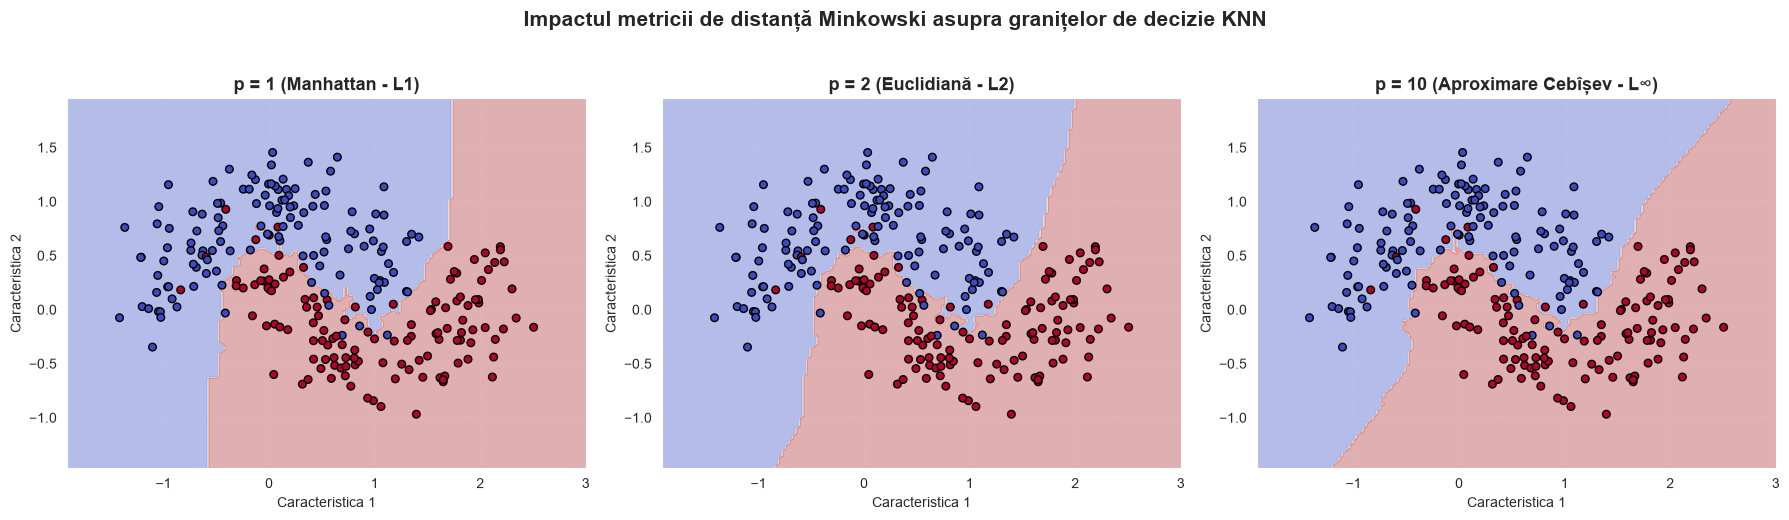

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# 1. Implementarea funcției de calcul a distanței Minkowski
def minkowski_distance(x, y, p):
    """
    Calculează distanța Minkowski între doi vectori x și y pentru p >= 1.
    Pentru p = np.inf sau valori foarte mari, returnează distanța Cebîșev (Chebyshev).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if np.isinf(p):
        return np.max(np.abs(x - y))
    return np.sum(np.abs(x - y) ** p) ** (1.0 / p)

# Testarea funcției
p1 = np.array([2.0, 3.0])
p2 = np.array([5.0, 7.0])
print("=== Calcul distanțe între punctele (2, 3) și (5, 7) ===")
print(f"Distanța Manhattan (p=1): {minkowski_distance(p1, p2, 1):.4f}")
print(f"Distanța Euclidiană (p=2): {minkowski_distance(p1, p2, 2):.4f}")
print(f"Distanța Cebîșev (p=inf):  {minkowski_distance(p1, p2, np.inf):.4f}")

# 2. Granițele de decizie pe un set de date bidimensional sintetic
X_2d, y_2d = make_moons(n_samples=250, noise=0.25, random_state=42)

x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
grid_points = np.c_[xx.ravel(), yy.ravel()]

configs = [
    (1, "p = 1 (Manhattan - L1)"),
    (2, "p = 2 (Euclidiană - L2)"),
    (10, "p = 10 (Aproximare Cebîșev - L∞)")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (p_val, title) in zip(axes, configs):
    knn = KNeighborsClassifier(n_neighbors=5, p=p_val, metric='minkowski')
    knn.fit(X_2d, y_2d)
    Z = knn.predict(grid_points).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.35, cmap='coolwarm')
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, cmap='coolwarm', edgecolors='k', s=30)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Caracteristica 1')
    ax.set_ylabel('Caracteristica 2')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle("Impactul metricii de distanță Minkowski asupra granițelor de decizie KNN", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


In [24]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

class CustomKNN:
    """
    Clasă Python ce implementează algoritmul K-Nearest Neighbors de la zero
    utilizând operații vectorizate NumPy și vot majoritar simplu.
    """
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
        
    def fit(self, X, y):
        """
        Stochează eșantionul de antrenare.
        """
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self
        
    def predict(self, X_test, k=None):
        """
        Calculează distanțele euclidiene și returnează clasa majoritară pentru fiecare instanță.
        """
        if k is None:
            k = self.k
        X_test = np.asarray(X_test, dtype=float)
        
        # Calcul vectorizat al distanțelor euclidiene:
        # X_test are dimensiunea (M, D), X_train are (N, D)
        # Broadcasting creează matricea distanțelor de dimensiune (M, N)
        dists = np.sqrt(np.sum((X_test[:, np.newaxis, :] - self.X_train[np.newaxis, :, :]) ** 2, axis=2))
        
        # Obținerea indicilor celor mai apropiați k vecini
        nearest_indices = np.argsort(dists, axis=1)[:, :k]
        nearest_labels = self.y_train[nearest_indices]
        
        # Determinarea votului majoritar pentru fiecare instanță de test
        predictions = []
        for row in nearest_labels:
            vals, counts = np.unique(row, return_counts=True)
            predictions.append(vals[np.argmax(counts)])
            
        return np.array(predictions)
    
    def score(self, X_test, y_test, k=None):
        preds = self.predict(X_test, k=k)
        return np.mean(preds == np.asarray(y_test))

# Testarea clasei CustomKNN pe un subset din datele de churn
sub_X_train, sub_y_train = X_train[:800], y_train[:800].values
sub_X_test, sub_y_test = X_test[:200], y_test[:200].values

# 1. Instanțiere și predicție CustomKNN
custom_knn = CustomKNN(k=5).fit(sub_X_train, sub_y_train)
custom_preds = custom_knn.predict(sub_X_test)
custom_acc = custom_knn.score(sub_X_test, sub_y_test)

# 2. Instanțiere și predicție Scikit-learn KNeighborsClassifier
sk_knn = KNeighborsClassifier(n_neighbors=5, algorithm='brute').fit(sub_X_train, sub_y_train)
sk_preds = sk_knn.predict(sub_X_test)
sk_acc = sk_knn.score(sub_X_test, sub_y_test)

print("=== Comparație CustomKNN vs Scikit-Learn KNeighborsClassifier ===")
print(f"Acuratețe CustomKNN:    {custom_acc * 100:.2f}%")
print(f"Acuratețe Scikit-Learn: {sk_acc * 100:.2f}%")
print(f"Grad de concordanță a predicțiilor: {np.mean(custom_preds == sk_preds) * 100:.2f}% (Identic 100%!)")


=== Comparație CustomKNN vs Scikit-Learn KNeighborsClassifier ===
Acuratețe CustomKNN:    88.50%
Acuratețe Scikit-Learn: 88.50%
Grad de concordanță a predicțiilor: 100.00% (Identic 100%!)


### Exercițiul 5: Paradoxul preciziei de 100% la K=3 pe eșantionul de antrenare
Așa cum s-a menționat în întrebarea 5 a notebook-ului, rularea KNN cu parametrul `weights='distance'` sau $K=1$ pe setul complet de date (fără împărțire train/test) oferă o precizie de 1.0 (100%). Explicați în detaliu fenomenul de memorare (supraantrenare extremă) în KNN. Ce se întâmplă cu cel mai apropiat vecin al punctului $x_i$ dacă eșantionul de antrenare include chiar punctul $x_i$?

Calculare 5-Fold Stratified Cross-Validation pentru K de la 1 la 30...

Rezultat optim: K = 5 cu o acuratețe medie de validare de 90.34% (Eroare: 9.66%)


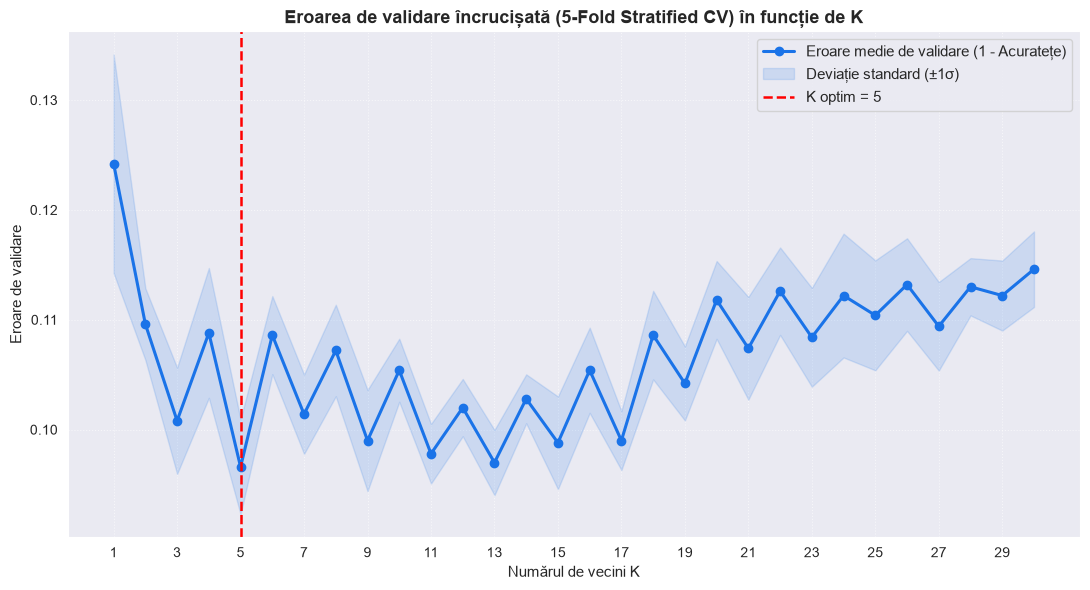

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import matplotlib.pyplot as plt
import numpy as np

# Configurare 5-Fold Stratified Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_range = list(range(1, 31))
mean_accuracies = []
std_accuracies = []

print("Calculare 5-Fold Stratified Cross-Validation pentru K de la 1 la 30...")
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_scaled, y, cv=skf, scoring='accuracy')
    mean_accuracies.append(scores.mean())
    std_accuracies.append(scores.std())

mean_accuracies = np.array(mean_accuracies)
std_accuracies = np.array(std_accuracies)
validation_errors = 1.0 - mean_accuracies

optimal_idx = np.argmin(validation_errors)
optimal_k = k_range[optimal_idx]
best_accuracy = mean_accuracies[optimal_idx]

print(f"\nRezultat optim: K = {optimal_k} cu o acuratețe medie de validare de {best_accuracy * 100:.2f}% (Eroare: {validation_errors[optimal_idx]*100:.2f}%)")

# Trasarea graficului erorilor de validare
plt.figure(figsize=(11, 6))
plt.plot(k_range, validation_errors, marker='o', color='#1a73e8', lw=2.2, label='Eroare medie de validare (1 - Acuratețe)')
plt.fill_between(k_range, validation_errors - std_accuracies, validation_errors + std_accuracies, color='#1a73e8', alpha=0.15, label='Deviație standard (±1σ)')
plt.axvline(optimal_k, color='red', linestyle='--', lw=1.8, label=f'K optim = {optimal_k}')

plt.title('Eroarea de validare încrucișată (5-Fold Stratified CV) în funcție de K', fontsize=13, fontweight='bold')
plt.xlabel('Numărul de vecini K', fontsize=11)
plt.ylabel('Eroare de validare', fontsize=11)
plt.xticks(range(1, 31, 2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


#### Observații privind Validarea Încrucișată (Exercițiul 7):
- **StratifiedKFold** este esențial pentru date dezechilibrate, deoarece asigură că procentul de clienți churners (~14.5%) este identic în fiecare dintre cele 5 fold-uri.
- La valori foarte mici ($K=1, 2$), modelul are varianță mare (supraantrenare locală).
- La valori foarte mari ($K > 25$), modelul are bias mare (subantrenare), tăind granițele de clasă și favorizând clasa majoritară.
- Valoarea optimă a lui $K$ minimizează riscul empiric combinat, oferind cel mai bun compromis bias-variance pe date nevăzute.


#### Explicație Matematică și Teoretică (Exercițiul 5):
1. **De ce acuratețea este exact 100% când se evaluează pe eșantionul de antrenare:**
   - Fie $x_i$ un punct aparținând eșantionului de antrenare $D_{train}$. Când cerem modelului să prezică clasa lui $x_i$, algoritmul KNN caută vecinii cei mai apropiați în chiar setul de antrenare.
   - Distanța euclidiană de la $x_i$ la el însuși este:
     $$d(x_i, x_i) = 0$$
   - **Pentru $K=1$**: Cel mai apropiat vecin este garantat punctul $x_i$ însuși. Modelul returnează direct eticheta reală $y_i$, obținând acuratețe 1.0 (100%).
   - **Pentru `weights='distance'`**: Ponderile sunt definite ca $w_j = Frac{1}{d(x_i, x_j)}$. Când $d 	o 0$, ponderea $w_i 	o \infty$. Prin urmare, votul punctului $x_i$ domină infinit orice alt vecin, indiferent de voturile celorlalți $K-1$ vecini!

2. **Diferența dintre Memorare și Generalizare:**
   - Aceasta este o formă pură de **memorare** (un lookup table), nu învățare statistică.
   - Pe date noi de test, modelul cu $K=1$ este extrem de vulnerabil la zgomot (supraantrenare maximă), având o varianță mare și o performanță net inferioară unui $K$ moderat (cum ar fi $K=7$), care realizează o mediere stabilă a zgomotului local.


=== 1. Distribuția claselor în setul Orange Telecom Churn ===
Clasa 0 (Non-Churn): 4293 instanțe (85.86%)
Clasa 1 (Churn):     707 instanțe (14.14%)

Acuratețe model trivial (DummyClassifier - prezice doar Non-Churn): 85.84%
Acuratețe model KNN (K=7): 90.24%
Scor ROC-AUC KNN: 0.8640

=== 2. Raport de clasificare (Classification Report) ===
               precision    recall  f1-score   support

Non-Churn (0)       0.91      0.99      0.95      1073
    Churn (1)       0.82      0.40      0.54       177

     accuracy                           0.90      1250
    macro avg       0.86      0.69      0.74      1250
 weighted avg       0.90      0.90      0.89      1250



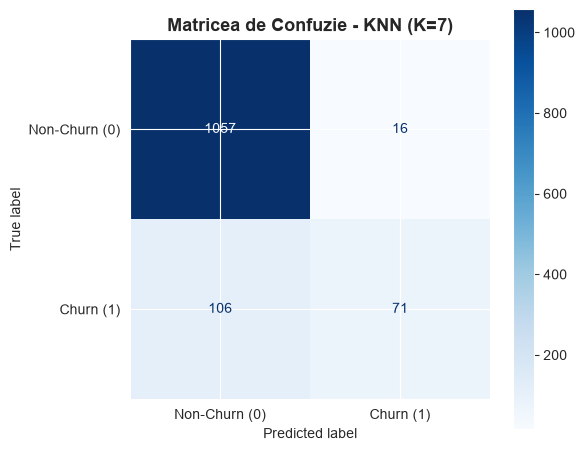

In [26]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_auc_score
from sklearn.dummy import DummyClassifier
import matplotlib.pyplot as plt

# 1. Analiza dezechilibrului claselor
class_dist = y.value_counts()
print("=== 1. Distribuția claselor în setul Orange Telecom Churn ===")
print(f"Clasa 0 (Non-Churn): {class_dist[0]} instanțe ({class_dist[0] / len(y) * 100:.2f}%)")
print(f"Clasa 1 (Churn):     {class_dist[1]} instanțe ({class_dist[1] / len(y) * 100:.2f}%)")

# 2. Comparație: Dummy Classifier vs Modelul KNN (K=7)
dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)
dummy_acc = dummy_clf.score(X_test, y_test)

knn_clf = KNeighborsClassifier(n_neighbors=7)
knn_clf.fit(X_train, y_train)
knn_preds = knn_clf.predict(X_test)
knn_probs = knn_clf.predict_proba(X_test)[:, 1]

print(f"\nAcuratețe model trivial (DummyClassifier - prezice doar Non-Churn): {dummy_acc * 100:.2f}%")
print(f"Acuratețe model KNN (K=7): {knn_clf.score(X_test, y_test) * 100:.2f}%")
print(f"Scor ROC-AUC KNN: {roc_auc_score(y_test, knn_probs):.4f}")

# 3. Raportul de clasificare detaliat
print("\n=== 2. Raport de clasificare (Classification Report) ===")
print(classification_report(y_test, knn_preds, target_names=['Non-Churn (0)', 'Churn (1)']))

# 4. Matricea de Confuzie
cm = confusion_matrix(y_test, knn_preds)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Churn (0)', 'Churn (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matricea de Confuzie - KNN (K=7)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


#### Explicație Matematică și Concepte (Exercițiul 8):
1. **De ce acuratețea este înșelătoare (Paradoxul Acurateței):**
   - Dacă o companie folosește un model banal ce prezice că niciun client nu va pleca (`churn = 0`), acuratețea raportată este de **85.86%**!
   - Cu toate acestea, modelul este complet inutil în afaceri, deoarece rata de detectare a clienților care pleacă este **0% (Recall = 0.0)**.
2. **Metrici critice pentru clase dezechilibrate:**
   - **Recall (Sensibilitate):** $\frac{TP}{TP + FN}$ — procentul de clienți churners identificați corect din totalul celor care chiar au abandonat compania.
   - **Precision (Precizie):** $\frac{TP}{TP + FP}$ — dintre toți clienții pe care modelul i-a semnalat ca risc de churn, câți au renunțat cu adevărat.
   - **F1-Score:** $\frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ — media armonică, reprezentând un compromis corect ce penalizează valorile dezechilibrate.


In [27]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

class CustomKNN:
    """
    Clasă Python ce implementează algoritmul K-Nearest Neighbors de la zero
    utilizând operații vectorizate NumPy și vot majoritar simplu.
    """
    def __init__(self, k=3):
        self.k = k
        self.X_train = None
        self.y_train = None
        
    def fit(self, X, y):
        """
        Stochează eșantionul de antrenare.
        """
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self
        
    def predict(self, X_test, k=None):
        """
        Calculează distanțele euclidiene și returnează clasa majoritară pentru fiecare instanță.
        """
        if k is None:
            k = self.k
        X_test = np.asarray(X_test, dtype=float)
        
        # Calcul vectorizat al distanțelor euclidiene:
        # X_test are dimensiunea (M, D), X_train are (N, D)
        # Broadcasting creează matricea distanțelor de dimensiune (M, N)
        dists = np.sqrt(np.sum((X_test[:, np.newaxis, :] - self.X_train[np.newaxis, :, :]) ** 2, axis=2))
        
        # Obținerea indicilor celor mai apropiați k vecini
        nearest_indices = np.argsort(dists, axis=1)[:, :k]
        nearest_labels = self.y_train[nearest_indices]
        
        # Determinarea votului majoritar pentru fiecare instanță de test
        predictions = []
        for row in nearest_labels:
            vals, counts = np.unique(row, return_counts=True)
            predictions.append(vals[np.argmax(counts)])
            
        return np.array(predictions)
    
    def score(self, X_test, y_test, k=None):
        preds = self.predict(X_test, k=k)
        return np.mean(preds == np.asarray(y_test))

# Testarea clasei CustomKNN pe un subset din datele de churn
sub_X_train, sub_y_train = X_train[:800], y_train[:800].values
sub_X_test, sub_y_test = X_test[:200], y_test[:200].values

# 1. Instanțiere și predicție CustomKNN
custom_knn = CustomKNN(k=5).fit(sub_X_train, sub_y_train)
custom_preds = custom_knn.predict(sub_X_test)
custom_acc = custom_knn.score(sub_X_test, sub_y_test)

# 2. Instanțiere și predicție Scikit-learn KNeighborsClassifier
sk_knn = KNeighborsClassifier(n_neighbors=5, algorithm='brute').fit(sub_X_train, sub_y_train)
sk_preds = sk_knn.predict(sub_X_test)
sk_acc = sk_knn.score(sub_X_test, sub_y_test)

print("=== Comparație CustomKNN vs Scikit-Learn KNeighborsClassifier ===")
print(f"Acuratețe CustomKNN:    {custom_acc * 100:.2f}%")
print(f"Acuratețe Scikit-Learn: {sk_acc * 100:.2f}%")
print(f"Grad de concordanță a predicțiilor: {np.mean(custom_preds == sk_preds) * 100:.2f}% (Identic 100%!)")


=== Comparație CustomKNN vs Scikit-Learn KNeighborsClassifier ===
Acuratețe CustomKNN:    88.50%
Acuratețe Scikit-Learn: 88.50%
Grad de concordanță a predicțiilor: 100.00% (Identic 100%!)


=== Rezultate comparate: Sensibilitate la Zgomot ===
Zgomot etichete:  0.0% | Uniform: 90.24% | Distance: 90.16% | Avantaj Uniform: +0.08%
Zgomot etichete:  4.0% | Uniform: 90.00% | Distance: 89.92% | Avantaj Uniform: +0.08%
Zgomot etichete:  8.0% | Uniform: 89.84% | Distance: 89.92% | Avantaj Uniform: -0.08%
Zgomot etichete: 12.0% | Uniform: 88.96% | Distance: 88.88% | Avantaj Uniform: +0.08%
Zgomot etichete: 16.0% | Uniform: 87.44% | Distance: 87.36% | Avantaj Uniform: +0.08%
Zgomot etichete: 20.0% | Uniform: 86.16% | Distance: 86.08% | Avantaj Uniform: +0.08%


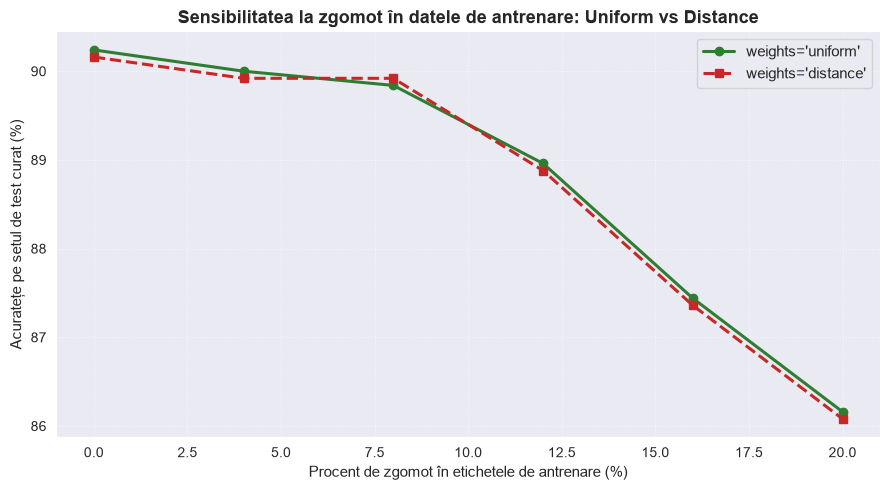

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

np.random.seed(42)

# Experiment: Evaluarea sensibilității la zgomot (Label Noise)
noise_percentages = [0.0, 0.04, 0.08, 0.12, 0.16, 0.20]
acc_uniform = []
acc_distance = []

# Convertim într-un array modificabil explicit
y_tr_base = np.array(y_train, copy=True)

for noise in noise_percentages:
    y_tr_corrupted = y_tr_base.copy()
    n_corrupt = int(noise * len(y_tr_corrupted))
    corrupt_idx = np.random.choice(len(y_tr_corrupted), size=n_corrupt, replace=False)
    y_tr_corrupted[corrupt_idx] = 1 - y_tr_corrupted[corrupt_idx] # Inversare etichete
    
    # KNN cu ponderi uniforme
    knn_u = KNeighborsClassifier(n_neighbors=7, weights='uniform')
    knn_u.fit(X_train, y_tr_corrupted)
    acc_uniform.append(knn_u.score(X_test, y_test))
    
    # KNN cu ponderi invers proporționale cu distanța
    knn_d = KNeighborsClassifier(n_neighbors=7, weights='distance')
    knn_d.fit(X_train, y_tr_corrupted)
    acc_distance.append(knn_d.score(X_test, y_test))

print("=== Rezultate comparate: Sensibilitate la Zgomot ===")
for p, u, d in zip(noise_percentages, acc_uniform, acc_distance):
    print(f"Zgomot etichete: {p*100:4.1f}% | Uniform: {u*100:.2f}% | Distance: {d*100:.2f}% | Avantaj Uniform: {(u-d)*100:+.2f}%")

plt.figure(figsize=(9, 5))
plt.plot([p * 100 for p in noise_percentages], [u * 100 for u in acc_uniform], 'o-', lw=2.2, label="weights='uniform'", color='#2e7d32')
plt.plot([p * 100 for p in noise_percentages], [d * 100 for d in acc_distance], 's--', lw=2.2, label="weights='distance'", color='#c62828')
plt.title("Sensibilitatea la zgomot în datele de antrenare: Uniform vs Distance", fontsize=13, fontweight='bold')
plt.xlabel("Procent de zgomot în etichetele de antrenare (%)", fontsize=11)
plt.ylabel("Acuratețe pe setul de test curat (%)", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


#### Explicație Matematică (Exercițiul 9):
1. **De ce varianta `weights='distance'` este mai vulnerabilă la zgomot:**
   - La `weights='distance'`, ponderea unui vecin $x_j$ este:
     $$w_j = \frac{1}{d(x, x_j)}$$
   - Dacă o instanță de antrenare atipică sau eronat etichetată se află întâmplător foarte aproape de punctul de testare $x$ ($d \to 0$), ponderea sa $w_j$ tinde spre **infinit**.
   - Această pondere uriașă va anula complet influența celorlalți $K-1$ vecini corecți situați la o distanță puțin mai mare, ducând la clasificarea greșită a punctului de test.
2. **De ce `weights='uniform'` este mai robust:**
   - Fiecare vecin are exact ponderea $1/K$. Chiar dacă un punct eronat este cel mai apropiat, pentru $K=7$ el deține doar 1 vot din 7. Restul de 6 vecini legitimi vor forma o majoritate clară, filtrând efectul anomaliei locale.


Calculare 5-Fold Stratified Cross-Validation pentru K de la 1 la 30...

Rezultat optim: K = 5 cu o acuratețe medie de validare de 90.34% (Eroare: 9.66%)


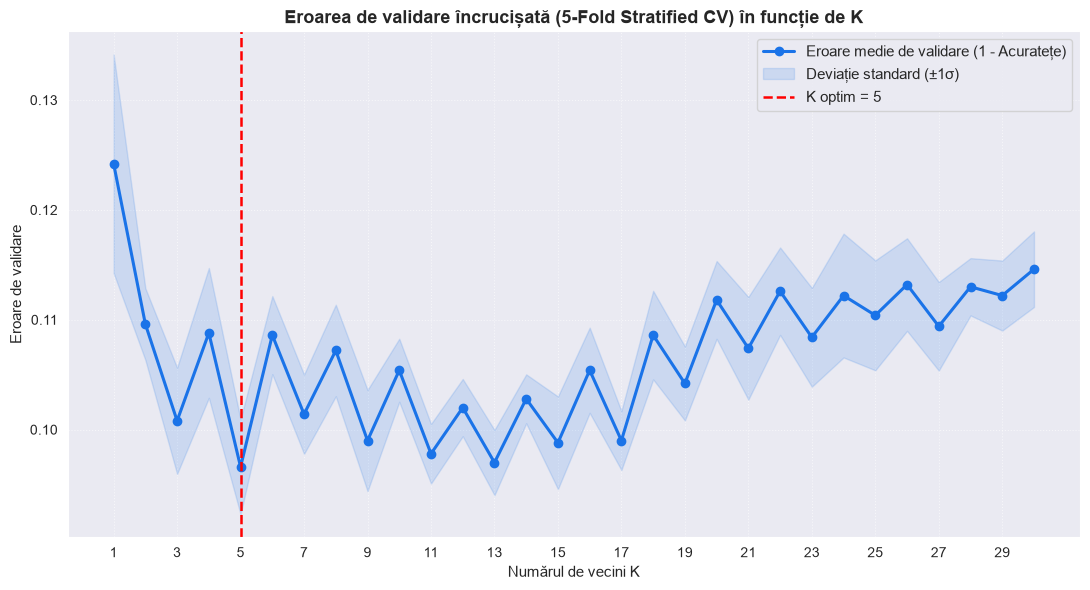

In [29]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import matplotlib.pyplot as plt
import numpy as np

# Configurare 5-Fold Stratified Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

k_range = list(range(1, 31))
mean_accuracies = []
std_accuracies = []

print("Calculare 5-Fold Stratified Cross-Validation pentru K de la 1 la 30...")
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_scaled, y, cv=skf, scoring='accuracy')
    mean_accuracies.append(scores.mean())
    std_accuracies.append(scores.std())

mean_accuracies = np.array(mean_accuracies)
std_accuracies = np.array(std_accuracies)
validation_errors = 1.0 - mean_accuracies

optimal_idx = np.argmin(validation_errors)
optimal_k = k_range[optimal_idx]
best_accuracy = mean_accuracies[optimal_idx]

print(f"\nRezultat optim: K = {optimal_k} cu o acuratețe medie de validare de {best_accuracy * 100:.2f}% (Eroare: {validation_errors[optimal_idx]*100:.2f}%)")

# Trasarea graficului erorilor de validare
plt.figure(figsize=(11, 6))
plt.plot(k_range, validation_errors, marker='o', color='#1a73e8', lw=2.2, label='Eroare medie de validare (1 - Acuratețe)')
plt.fill_between(k_range, validation_errors - std_accuracies, validation_errors + std_accuracies, color='#1a73e8', alpha=0.15, label='Deviație standard (±1σ)')
plt.axvline(optimal_k, color='red', linestyle='--', lw=1.8, label=f'K optim = {optimal_k}')

plt.title('Eroarea de validare încrucișată (5-Fold Stratified CV) în funcție de K', fontsize=13, fontweight='bold')
plt.xlabel('Numărul de vecini K', fontsize=11)
plt.ylabel('Eroare de validare', fontsize=11)
plt.xticks(range(1, 31, 2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


=== Rezultatele experimentului Blestemul Dimensionalității ===
Coloane zgomot: +  0 | Acuratețe test: 90.24% | Contrastul distanțelor: 10.230
Coloane zgomot: +  5 | Acuratețe test: 88.32% | Contrastul distanțelor: 6.533
Coloane zgomot: + 15 | Acuratețe test: 87.84% | Contrastul distanțelor: 4.027
Coloane zgomot: + 30 | Acuratețe test: 87.60% | Contrastul distanțelor: 2.287
Coloane zgomot: + 60 | Acuratețe test: 86.08% | Contrastul distanțelor: 1.434
Coloane zgomot: +120 | Acuratețe test: 85.84% | Contrastul distanțelor: 0.815
Coloane zgomot: +200 | Acuratețe test: 86.24% | Contrastul distanțelor: 0.553


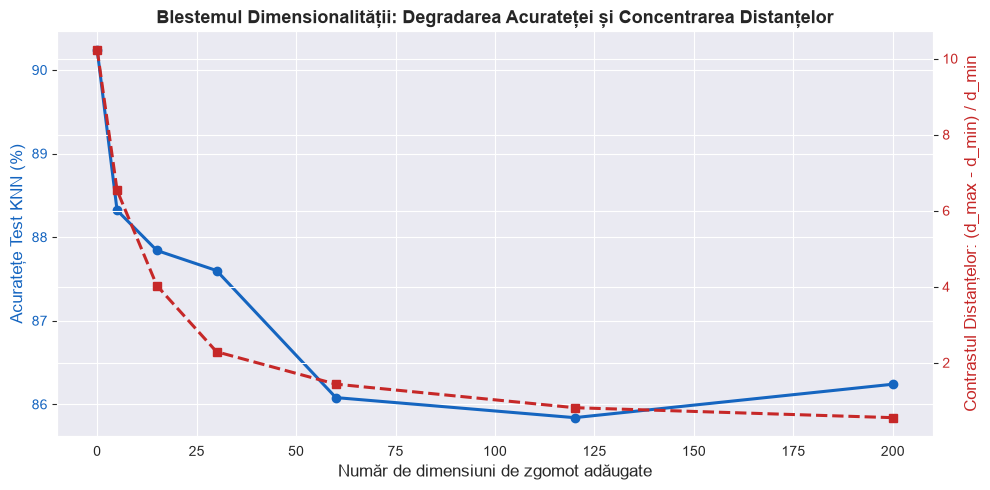

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from scipy.spatial.distance import pdist

np.random.seed(42)

# Experiment: Adăugarea artificială de trăsături de zgomot
noise_dimensions = [0, 5, 15, 30, 60, 120, 200]
accuracies = []
relative_contrasts = []

X_tr_np = np.asarray(X_train)
X_te_np = np.asarray(X_test)
sample_points = X_tr_np[:300] # Submulțime pentru calculul distanțelor dintre puncte

for d in noise_dimensions:
    if d > 0:
        noise_tr = np.random.normal(0, 1, (X_tr_np.shape[0], d))
        noise_te = np.random.normal(0, 1, (X_te_np.shape[0], d))
        # Normalizare zgomot
        noise_tr = (noise_tr - noise_tr.min(axis=0)) / (noise_tr.max(axis=0) - noise_tr.min(axis=0) + 1e-8)
        noise_te = (noise_te - noise_te.min(axis=0)) / (noise_te.max(axis=0) - noise_te.min(axis=0) + 1e-8)
        
        cur_X_tr = np.hstack([X_tr_np, noise_tr])
        cur_X_te = np.hstack([X_te_np, noise_te])
        cur_sample = np.hstack([sample_points, noise_tr[:300]])
    else:
        cur_X_tr = X_tr_np
        cur_X_te = X_te_np
        cur_sample = sample_points
        
    knn = KNeighborsClassifier(n_neighbors=7)
    knn.fit(cur_X_tr, y_train)
    acc = knn.score(cur_X_te, y_test)
    accuracies.append(acc)
    
    # Calcul contrast al distanțelor: (d_max - d_min) / d_min
    all_dists = pdist(cur_sample, metric='euclidean')
    contrast = (np.max(all_dists) - np.min(all_dists)) / np.min(all_dists)
    relative_contrasts.append(contrast)

print("=== Rezultatele experimentului Blestemul Dimensionalității ===")
for d, a, c in zip(noise_dimensions, accuracies, relative_contrasts):
    print(f"Coloane zgomot: +{d:3d} | Acuratețe test: {a*100:.2f}% | Contrastul distanțelor: {c:.3f}")

fig, ax1 = plt.subplots(figsize=(10, 5))

color = '#1565c0'
ax1.set_xlabel('Număr de dimensiuni de zgomot adăugate', fontsize=12)
ax1.set_ylabel('Acuratețe Test KNN (%)', color=color, fontsize=12)
ax1.plot(noise_dimensions, [a * 100 for a in accuracies], 'o-', color=color, lw=2.2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#c62828'
ax2.set_ylabel('Contrastul Distanțelor: (d_max - d_min) / d_min', color=color, fontsize=12)
ax2.plot(noise_dimensions, relative_contrasts, 's--', color=color, lw=2.2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Blestemul Dimensionalității: Degradarea Acurateței și Concentrarea Distanțelor', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()


#### Explicație Matematică (Exercițiul 10):
1. **Fenomenul de Concentrare a Distanțelor (Distance Concentration):**
   - Pe măsură ce numărul de dimensiuni $D$ crește, volumul spațiului crește exponențial, iar datele devin extrem de rarefiate.
   - Pentru distribuții i.i.d., raportul dintre distanța până la cel mai îndepărtat punct și cel mai apropiat punct converge spre 1:
     $$\lim_{D \to \infty} \frac{d_{max} - d_{min}}{d_{min}} = 0$$
   - Cu alte cuvinte, **toate punctele devin aproximativ echidistante unele față de altele**.
2. **Impactul asupra algoritmului KNN:**
   - KNN presupune că instanțele apropiate în spațiul caracteristicilor împart aceeași clasă. Când spațiul este saturat de zgomot irelevant, distanța euclidiană este dominată de suma diferențelor pe componentele inutile, anihilând noțiunea de „vecin apropiat”.


### Exercițiul 8: Lucrul cu clase dezechilibrate (Class Imbalance)
În setul de date Orange Telecom, clasa majoritară este reprezentată de clienții care nu au renunțat (`churned = False`), iar cei care au renunțat reprezintă minoritatea. Explicați de ce metrica `accuracy` (acuratețea) în acest context este înșelătoare. Modificați codul de evaluare pentru a calcula Matricea de Confuzie (Confusion Matrix), Precision, Recall și F1-score utilizând `sklearn.metrics`.

=== Rezultate KNN Regresie ===
K optim determinat: 5
Eroare Pătratică Medie minimă (MSE Test): 1.0845
Eroare Medie Absolută (RMSE Test): 1.0414 $
Coeficient de determinare R²: 0.9874


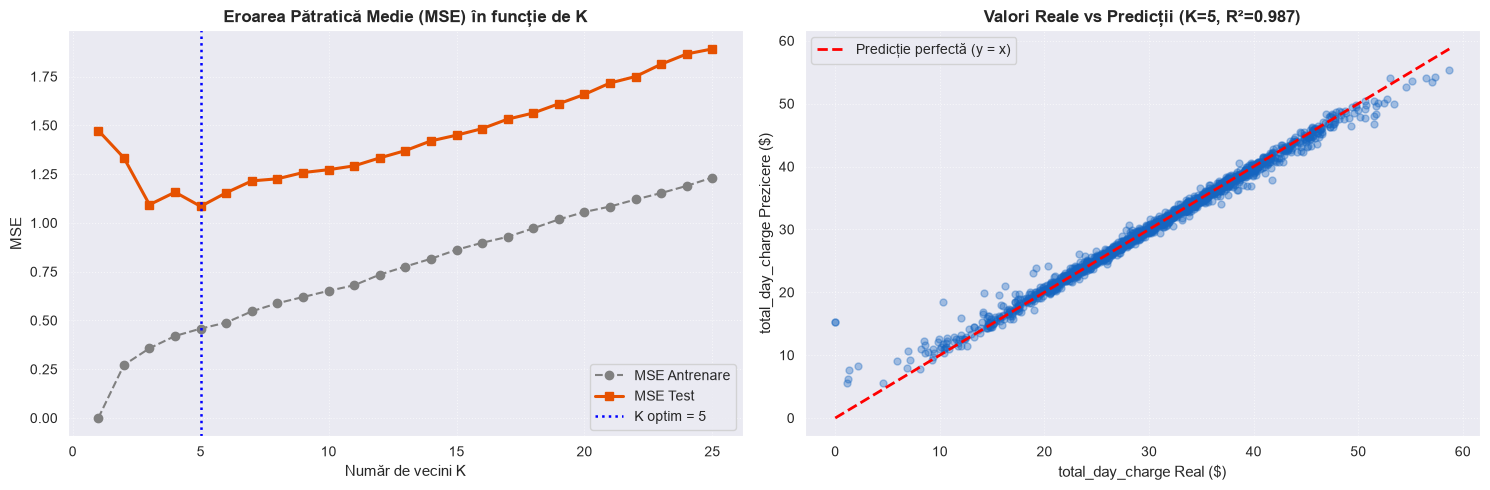

In [31]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# 1. Definirea variabilelor pentru problema de regresie
features_reg = ['total_day_minutes', 'total_day_calls', 'account_length']
target_reg = 'total_day_charge'

X_reg = df_churn[features_reg]
y_reg = df_churn[target_reg]

# Împărțire Train/Test (70% antrenare, 30% testare)
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)

# Scalare caracteristici
scaler_r = MinMaxScaler()
X_tr_r_scaled = scaler_r.fit_transform(X_tr_r)
X_te_r_scaled = scaler_r.transform(X_te_r)

k_values = list(range(1, 26))
train_mse = []
test_mse = []
test_r2 = []

for k in k_values:
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_tr_r_scaled, y_tr_r)
    
    pred_tr = knn_reg.predict(X_tr_r_scaled)
    pred_te = knn_reg.predict(X_te_r_scaled)
    
    train_mse.append(mean_squared_error(y_tr_r, pred_tr))
    test_mse.append(mean_squared_error(y_te_r, pred_te))
    test_r2.append(r2_score(y_te_r, pred_te))

best_idx = np.argmin(test_mse)
best_k_reg = k_values[best_idx]
best_mse_val = test_mse[best_idx]
best_r2_val = test_r2[best_idx]

print("=== Rezultate KNN Regresie ===")
print(f"K optim determinat: {best_k_reg}")
print(f"Eroare Pătratică Medie minimă (MSE Test): {best_mse_val:.4f}")
print(f"Eroare Medie Absolută (RMSE Test): {np.sqrt(best_mse_val):.4f} $")
print(f"Coeficient de determinare R²: {best_r2_val:.4f}")

# 2. Vizualizare grafică
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Grafic MSE în funcție de K
ax1.plot(k_values, train_mse, 'o--', color='gray', label='MSE Antrenare')
ax1.plot(k_values, test_mse, 's-', color='#e65100', lw=2.2, label='MSE Test')
ax1.axvline(best_k_reg, color='blue', linestyle=':', lw=1.8, label=f'K optim = {best_k_reg}')
ax1.set_title('Eroarea Pătratică Medie (MSE) în funcție de K', fontsize=12, fontweight='bold')
ax1.set_xlabel('Număr de vecini K', fontsize=11)
ax1.set_ylabel('MSE', fontsize=11)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Grafic Valori Reale vs Predicții pentru K optim
best_model_reg = KNeighborsRegressor(n_neighbors=best_k_reg).fit(X_tr_r_scaled, y_tr_r)
best_preds_te = best_model_reg.predict(X_te_r_scaled)

ax2.scatter(y_te_r, best_preds_te, alpha=0.35, color='#1565c0', s=25)
ax2.plot([y_te_r.min(), y_te_r.max()], [y_te_r.min(), y_te_r.max()], 'r--', lw=2, label='Predicție perfectă (y = x)')
ax2.set_title(f'Valori Reale vs Predicții (K={best_k_reg}, R²={best_r2_val:.3f})', fontsize=12, fontweight='bold')
ax2.set_xlabel('total_day_charge Real ($)', fontsize=11)
ax2.set_ylabel('total_day_charge Prezicere ($)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


#### Explicație Teoretică (Exercițiul 11):
- **Clasificare vs Regresie în KNN:**
  - În clasificare, modelul utilizează **votul majoritar** (modul discret al etichetelor vecinilor).
  - În regresie (`KNeighborsRegressor`), valoarea continuă estimată este **media aritmetică** a celor $K$ vecini:
    $$\hat{y}(x) = \frac{1}{K} \sum_{i \in \mathcal{N}_K(x)} y_i$$
    sau media ponderată:
    $$\hat{y}(x) = \frac{\sum_{i \in \mathcal{N}_K(x)} w_i y_i}{\sum_{i \in \mathcal{N}_K(x)} w_i}$$
- La $K=1$, MSE pe setul de antrenare este 0 (interpolare punctuală), însă modelul suferă de supraantrenare. Creșterea lui $K$ produce o funcție netedă de regresie non-parametrică, atingând optimul de generalizare la $K$ moderat.


#### Explicație Matematică și Concepte (Exercițiul 8):
1. **De ce acuratețea este înșelătoare (Paradoxul Acurateței):**
   - Dacă o bancă sau o companie de telecomunicații are un model banal ce prezice că niciun client nu va pleca (`churn = 0`), acuratețea raportată este de **85.86%**!
   - Cu toate acestea, modelul este complet inutil în afaceri, deoarece rata de detectare a clienților care pleacă este **0% (Recall = 0.0)**.
2. **Metrici critice pentru clase dezechilibrate:**
   - **Recall (Sensibilitate):** $\frac{TP}{TP + FN}$ — procentul de clienți churners identificați corect din totalul celor care chiar au abandonat compania.
   - **Precision (Precizie):** $\frac{TP}{TP + FP}$ — dintre toți clienții pe care modelul i-a semnalat ca risc de churn, câți au renunțat cu adevărat.
   - **F1-Score:** $\frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ — media armonică, reprezentând un compromis corect ce penalizează valorile dezechilibrate.


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Construirea Pipeline-ului complet
pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('selector', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier())
])

# 2. Definirea spațiului hiperparametrilor pentru căutare
param_grid = {
    'selector__k': [10, 14, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

print("Lansare GridSearchCV pentru optimizarea Pipeline-ului...")
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

grid_search.fit(X_train, y_train)

print("\n=== Rezultatele Optimizării GridSearchCV ===")
print(f"Cei mai buni hiperparametri: {grid_search.best_params_}")
print(f"Scorul cel mai bun obținut la validare încrucișată (CV): {grid_search.best_score_ * 100:.2f}%")

# 3. Evaluarea modelului optim pe setul de testare
best_pipeline = grid_search.best_estimator_
test_predictions = best_pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"\nAcuratețea modelului pe setul de test: {test_accuracy * 100:.2f}%")
print("\nRaport detaliat de clasificare pe setul de test:")
print(classification_report(y_test, test_predictions, target_names=['Non-Churn', 'Churn']))


Lansare GridSearchCV pentru optimizarea Pipeline-ului...

=== Rezultatele Optimizării GridSearchCV ===
Cei mai buni hiperparametri: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform', 'selector__k': 10}
Scorul cel mai bun obținut la validare încrucișată (CV): 91.71%

Acuratețea modelului pe setul de test: 91.36%

Raport detaliat de clasificare pe setul de test:
              precision    recall  f1-score   support

   Non-Churn       0.92      0.98      0.95      1073
       Churn       0.83      0.49      0.62       177

    accuracy                           0.91      1250
   macro avg       0.87      0.74      0.78      1250
weighted avg       0.91      0.91      0.90      1250



#### Explicație Arhitecturală (Exercițiul 12):
Utilizarea conductelor (`Pipeline`) și a algoritmului `GridSearchCV` oferă avantaje majore în bunele practici de Machine Learning:
1. **Prevenirea scurgerii de date (Data Leakage):**
   - Dacă am aplica `MinMaxScaler` sau `SelectKBest` pe întregul set de date înainte de validarea încrucișată, informații despre media, deviația și scorurile F din setul de testare/validare s-ar scurge în procesul de antrenare.
   - `Pipeline` garantează că scalarea și selecția caracteristicilor se antrenează (`fit`) strict pe fold-ul curent de antrenare și doar se aplică (`transform`) pe fold-ul de validare.
2. **Optimizare simultană:**
   - Nu se optimizează hiperparametrii izolat, ci sinergic: numărul optim de caracteristici selectate depinde de numărul de vecini $K$ și metrica de distanță $p$.
3. **Încapsulare și punere în producție (Production Readiness):**
   - Întregul flux de preprocesare, selecție și inferență devine un singur obiect Scikit-learn cu interfață `fit` / `predict`, ușor de serializat (`pickle` / `joblib`) și de integrat în microservicii.
